In [1]:
import pandas as pd
import numpy as np
import boto3
import matplotlib.pyplot as plt
import seaborn as sns

bucket = "insurance-pricing-model-akshayaa"

# Load raw data
freq = pd.read_csv(f"s3://{bucket}/freMTPL2freq.csv")
sev = pd.read_csv(f"s3://{bucket}/freMTPL2sev.csv")

C:\Users\prish\OneDrive\Desktop\Insurance Project\Insurance-Underwriting-Pricing-Model\venv\lib\site-packages\fsspec\registry.py:305: UserWarning: Your installed version of s3fs is very old and known to cause
severe performance issues, see also https://github.com/dask/dask/issues/10276

To fix, you should specify a lower version bound on s3fs, or
update the current installation.

  warnings.warn(s3_msg)


In [2]:
df_freq=pd.DataFrame(freq)
df_sev=pd.DataFrame(sev)

In [3]:
df_freq.head()

,IDpol,ClaimNb,Exposure,Area,VehPower,VehAge,DrivAge,BonusMalus,VehBrand,VehGas,Density,Region
0,1.0,1,0.10,D,5,0,55,50,B12,Regular,1217,R82
1,3.0,1,0.77,D,5,0,55,50,B12,Regular,1217,R82
2,5.0,1,0.75,B,6,2,52,50,B12,Diesel,54,R22
3,10.0,1,0.09,B,7,0,46,50,B12,Diesel,76,R72
4,11.0,1,0.84,B,7,0,46,50,B12,Diesel,76,R72


### Cleaning

In [4]:
# Type consistency
df_freq['IDpol'] = df_freq['IDpol'].astype(int)
df_sev['IDpol'] = df_sev['IDpol'].astype(int)

In [5]:
df_freq = df_freq.drop(columns=['Area'])

# Log transforming Desnity to log(Density)
df_freq['log_density'] = np.log1p(df_freq['Density'])

# Dropping density after transformation
df_freq = df_freq.drop(columns=['Density'])

In [6]:
# Capping outliers to 5 for ClaimNB
df_freq['ClaimNb'] = df_freq['ClaimNb'].clip(upper=5)

# Filtering out rows for which Exposure <= 1.0
df_freq=df_freq[df_freq['Exposure']<=1.0]
print(df_freq.shape)

(676789, 11)


### Joining two datasets on IDpol

In [7]:
sev_agg = sev.groupby('IDpol', as_index=False)['ClaimAmount'].sum()
df_joined = df_freq.merge(sev_agg, on='IDpol', how='left')
df_joined['ClaimAmount'] = df_joined['ClaimAmount'].fillna(0)

print("df_joined shape:", df_joined.shape)
print(df_joined.head())

df_joined shape: (676789, 12)
   IDpol  ClaimNb  Exposure  VehPower  VehAge  DrivAge  BonusMalus VehBrand  \
0      1        1      0.10         5       0       55          50      B12   
1      3        1      0.77         5       0       55          50      B12   
2      5        1      0.75         6       2       52          50      B12   
3     10        1      0.09         7       0       46          50      B12   
4     11        1      0.84         7       0       46          50      B12   

    VehGas Region  log_density  ClaimAmount  
0  Regular    R82     7.104965          0.0  
1  Regular    R82     7.104965          0.0  
2   Diesel    R22     4.007333          0.0  
3   Diesel    R72     4.343805          0.0  
4   Diesel    R72     4.343805          0.0  


### Dealing with Vehicle Brands: grouping small/rare categories together "Other"; threshold is <2-3% of the portfolio. 

In [8]:
print(df_joined['VehBrand'].value_counts())

VehBrand
B12    165959
B1     162407
B2     159491
B3      53266
B5      34692
B6      28483
B4      25143
B10     17640
B11     13531
B13     12147
B14      4030
Name: count, dtype: int64


In [9]:
threshold = 0.02  # group any brand representing less than 2% of total policies
brand_counts = df_joined['VehBrand'].value_counts(normalize=True)
rare_brands = brand_counts[brand_counts < threshold].index.tolist()

print("Brands to be grouped as 'Other':", rare_brands)
print(f"Combined 'Other' share: {brand_counts[rare_brands].sum()*100:.2f}%")

Brands to be grouped as 'Other': ['B11', 'B13', 'B14']
Combined 'Other' share: 4.39%


In [10]:
df_joined['VehBrand_grouped'] = df_joined['VehBrand'].apply(lambda x: 'Other' if x in rare_brands else x)

print(df_joined['VehBrand_grouped'].value_counts())

VehBrand_grouped
B12      165959
B1       162407
B2       159491
B3        53266
B5        34692
Other     29708
B6        28483
B4        25143
B10       17640
Name: count, dtype: int64


In [11]:
df_joined['VehGas_binary'] = (df_joined['VehGas'] == 'Diesel').astype(int)
# VehGas_binary = 1 represents Diesel

print(df_joined[['VehGas', 'VehGas_binary']].drop_duplicates())

    VehGas  VehGas_binary
0  Regular              0
2   Diesel              1


In [12]:
df_encoded = pd.get_dummies(df_joined, columns=['VehBrand_grouped', 'Region'], drop_first=True)

print(df_encoded.shape)
print(df_encoded.columns.tolist())

(676789, 41)
['IDpol', 'ClaimNb', 'Exposure', 'VehPower', 'VehAge', 'DrivAge', 'BonusMalus', 'VehBrand', 'VehGas', 'log_density', 'ClaimAmount', 'VehGas_binary', 'VehBrand_grouped_B10', 'VehBrand_grouped_B12', 'VehBrand_grouped_B2', 'VehBrand_grouped_B3', 'VehBrand_grouped_B4', 'VehBrand_grouped_B5', 'VehBrand_grouped_B6', 'VehBrand_grouped_Other', 'Region_R21', 'Region_R22', 'Region_R23', 'Region_R24', 'Region_R25', 'Region_R26', 'Region_R31', 'Region_R41', 'Region_R42', 'Region_R43', 'Region_R52', 'Region_R53', 'Region_R54', 'Region_R72', 'Region_R73', 'Region_R74', 'Region_R82', 'Region_R83', 'Region_R91', 'Region_R93', 'Region_R94']


In [13]:
df_encoded.head()

,IDpol,ClaimNb,Exposure,VehPower,VehAge,DrivAge,BonusMalus,VehBrand,VehGas,log_density,...,Region_R53,Region_R54,Region_R72,Region_R73,Region_R74,Region_R82,Region_R83,Region_R91,Region_R93,Region_R94
0,1,1,0.10,5,0,55,50,B12,Regular,7.104965,...,False,False,False,False,False,True,False,False,False,False
1,3,1,0.77,5,0,55,50,B12,Regular,7.104965,...,False,False,False,False,False,True,False,False,False,False
2,5,1,0.75,6,2,52,50,B12,Diesel,4.007333,...,False,False,False,False,False,False,False,False,False,False
3,10,1,0.09,7,0,46,50,B12,Diesel,4.343805,...,False,False,True,False,False,False,False,False,False,False
4,11,1,0.84,7,0,46,50,B12,Diesel,4.343805,...,False,False,True,False,False,False,False,False,False,False


In [14]:
dummy_cols = [col for col in df_encoded.columns if col.startswith('VehBrand_grouped_') or col.startswith('Region_')]
df_encoded[dummy_cols] = df_encoded[dummy_cols].astype(int)

print(df_encoded[dummy_cols].head())

   VehBrand_grouped_B10  VehBrand_grouped_B12  VehBrand_grouped_B2  \
0                     0                     1                    0   
1                     0                     1                    0   
2                     0                     1                    0   
3                     0                     1                    0   
4                     0                     1                    0   

   VehBrand_grouped_B3  VehBrand_grouped_B4  VehBrand_grouped_B5  \
0                    0                    0                    0   
1                    0                    0                    0   
2                    0                    0                    0   
3                    0                    0                    0   
4                    0                    0                    0   

   VehBrand_grouped_B6  VehBrand_grouped_Other  Region_R21  Region_R22  ...  \
0                    0                       0           0           0  ...   
1           

In [15]:
df_encoded = df_encoded.drop(columns=['VehBrand', 'VehGas'])
print(df_encoded.shape)
print(df_encoded.columns.tolist())

(676789, 39)
['IDpol', 'ClaimNb', 'Exposure', 'VehPower', 'VehAge', 'DrivAge', 'BonusMalus', 'log_density', 'ClaimAmount', 'VehGas_binary', 'VehBrand_grouped_B10', 'VehBrand_grouped_B12', 'VehBrand_grouped_B2', 'VehBrand_grouped_B3', 'VehBrand_grouped_B4', 'VehBrand_grouped_B5', 'VehBrand_grouped_B6', 'VehBrand_grouped_Other', 'Region_R21', 'Region_R22', 'Region_R23', 'Region_R24', 'Region_R25', 'Region_R26', 'Region_R31', 'Region_R41', 'Region_R42', 'Region_R43', 'Region_R52', 'Region_R53', 'Region_R54', 'Region_R72', 'Region_R73', 'Region_R74', 'Region_R82', 'Region_R83', 'Region_R91', 'Region_R93', 'Region_R94']


In [16]:
pd.set_option('display.max_columns', None)
print(df_encoded.head())

   IDpol  ClaimNb  Exposure  VehPower  VehAge  DrivAge  BonusMalus  \
0      1        1      0.10         5       0       55          50   
1      3        1      0.77         5       0       55          50   
2      5        1      0.75         6       2       52          50   
3     10        1      0.09         7       0       46          50   
4     11        1      0.84         7       0       46          50   

   log_density  ClaimAmount  VehGas_binary  VehBrand_grouped_B10  \
0     7.104965          0.0              0                     0   
1     7.104965          0.0              0                     0   
2     4.007333          0.0              1                     0   
3     4.343805          0.0              1                     0   
4     4.343805          0.0              1                     0   

   VehBrand_grouped_B12  VehBrand_grouped_B2  VehBrand_grouped_B3  \
0                     1                    0                    0   
1                     1         

### Frequency & Severity Modeling with train test split

In [17]:
freq_data = df_encoded.copy()
severity_data = df_encoded[(df_encoded['ClaimNb'] > 0) & (df_encoded['ClaimAmount'] > 0)]

print("Frequency population:", freq_data.shape)
print("Severity population:", severity_data.shape)

Frequency population: (676789, 39)
Severity population: (24893, 39)


In [18]:
from sklearn.model_selection import train_test_split

freq_train, freq_test = train_test_split(freq_data, test_size=0.2, random_state=42)
sev_train, sev_test = train_test_split(severity_data, test_size=0.2, random_state=42)

print("Freq train/test: ", freq_train.shape, freq_test.shape)
print("Severity train/test: ", sev_train.shape, sev_test.shape)

Freq train/test:  (541431, 39) (135358, 39)
Severity train/test:  (19914, 39) (4979, 39)


### Frequency Modeling

#### Poisson GLM - baseline model

In [19]:
import statsmodels.api as sm
import statsmodels.formula.api as smf

# Define feature columns (exclude IDpol, targets, and raw Exposure since it's used as offset)
exclude_cols = ['IDpol', 'ClaimNb', 'ClaimAmount', 'Exposure']
feature_cols = [col for col in freq_train.columns if col not in exclude_cols]

X_train = freq_train[feature_cols]
y_train = freq_train['ClaimNb']
offset_train = np.log(freq_train['Exposure'])

X_train_const = sm.add_constant(X_train)

poisson_model = sm.GLM(y_train, X_train_const, family=sm.families.Poisson(), offset=offset_train)
poisson_results = poisson_model.fit()

print(poisson_results.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:                ClaimNb   No. Observations:               541431
Model:                            GLM   Df Residuals:                   541395
Model Family:                 Poisson   Df Model:                           35
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:            -1.1464e+05
Date:                Wed, 23 Sep 2026   Deviance:                   1.7369e+05
Time:                        16:15:45   Pearson chi2:                 1.36e+06
No. Iterations:                     7   Pseudo R-squ. (CS):            0.01050
Covariance Type:            nonrobust                                         
                             coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------
const                     -4

### Conclusion: Which features actually matter?  
VehiclePower, VehicleAge, Driver’s Age, BonusMalus, log_Density, VehicleGas. <br>
Vehicle Brand: B12 and B5 <br>
Region-R24, Region-R41, Region-R53, Region-R82, Region-R83. <br>
Note: Log-transforming skewness rarely moves accuracy much in a GLM, but it's essential for correct coefficient magnitude, correct significance testing. The log version just does it more efficiently (fewer extreme residuals), so predictions at very low and very high densities are better calibrated.

### Inference:
Keeping all other features constant, 1-unit increase in BonusMalus multiplies expected claim frequency by exp(0.0223) ≈ 1.0226. <br>
Since -0.0445 is negative, switching from Regular (0) to Diesel (1) decreases the log of expected claim frequency. I.e. Diesel vehicles have lower claim frequency. <br>
Pseudo R² value for the model: 0.0105 is a roughly weak signal (between 0.20 and 0.40 is considered good). <br>

### Actionable Business Insights from GLM modeling:
Pricing: The insurer should seriously consider higher premiums for policyholders with the B12 vehicle brand and those living in regions like R82, R24 and R53. <br>
BonusMalus feature is a very strong predictor; a high BonusMalus score reliably signals higher claim frequency. So, insurers need to watch out for policies that have a high BonusMalus score. <br> 
Underwriting should tighten appetite in these high-frequency cells and grow selectively by offering discounts in low-risk regions like R41 and R83. <br>


### Predictions on Test Set

In [20]:
X_test = freq_test[feature_cols]
X_test_const = sm.add_constant(X_test, has_constant='add')
offset_test = np.log(freq_test['Exposure'])

freq_test['predicted'] = poisson_results.predict(X_test_const, offset=offset_test)

print(freq_test[['ClaimNb', 'Exposure', 'predicted']].head())

        ClaimNb  Exposure  predicted
8823          1      1.00   0.070031
220091        0      1.00   0.103242
510024        0      0.11   0.012740
207237        0      0.11   0.059274
48223         0      1.00   0.053729


Gini on test set: 0.2624164972789169


C:\Users\prish\AppData\Local\Temp\ipykernel_19840\1789365956.py:8: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  lorenz_area = np.trapz(df['cumulative_actual_pct'], df['cumulative_pop_pct'])


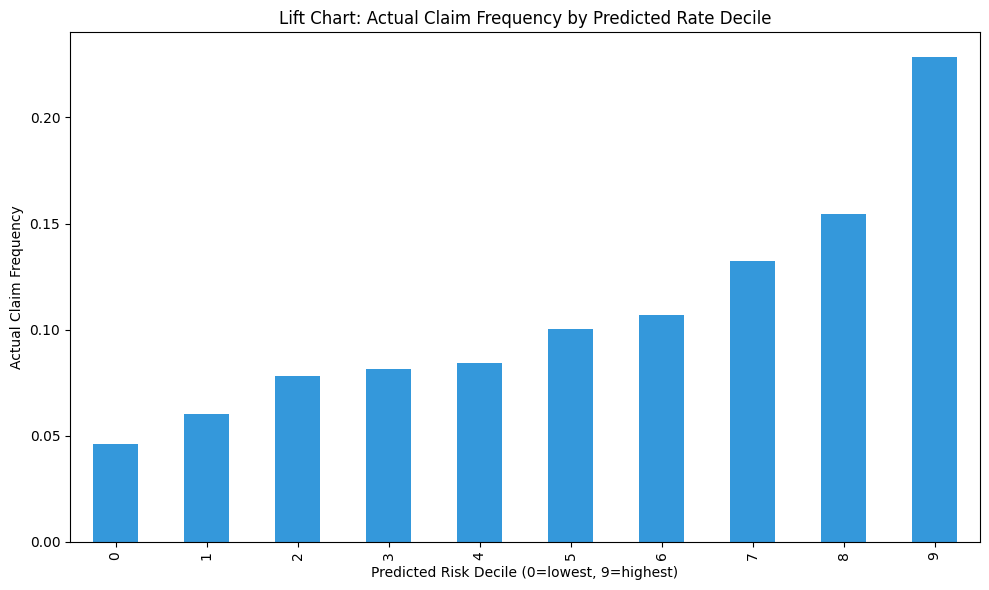

In [21]:
def gini(actual, predicted):
    df = pd.DataFrame({'actual': actual, 'predicted': predicted})
    df = df.sort_values('predicted', ascending=True).reset_index(drop=True)
    df['cumulative_actual'] = df['actual'].cumsum()
    df['cumulative_actual_pct'] = df['cumulative_actual'] / df['actual'].sum()
    df['cumulative_pop_pct'] = (df.index + 1) / len(df)
    
    lorenz_area = np.trapz(df['cumulative_actual_pct'], df['cumulative_pop_pct'])
    gini_coef = 1 - 2 * lorenz_area
    return gini_coef

print("Gini on test set:", gini(freq_test['ClaimNb'], freq_test['predicted']))


# ===== Lift Chart (corrected: bin by predicted RATE, not predicted count) =====
freq_test['predicted_rate'] = freq_test['predicted'] / freq_test['Exposure']
freq_test['decile'] = pd.qcut(freq_test['predicted_rate'], 10, labels=False, duplicates='drop')

lift = freq_test.groupby('decile')[['ClaimNb', 'Exposure']].apply(
    lambda x: x['ClaimNb'].sum() / x['Exposure'].sum()
)

plt.figure(figsize=(10,6))
lift.plot(kind='bar', color='#3498db')
plt.title('Lift Chart: Actual Claim Frequency by Predicted Rate Decile')
plt.xlabel('Predicted Risk Decile (0=lowest, 9=highest)')
plt.ylabel('Actual Claim Frequency')
plt.tight_layout()
plt.show()

### A 0.26 Gini means our model correctly orders risk better than random by a meaningful margin. In insurance pricing, ranking is what matters. We really don't need to predict the exact number of claims, we need to charge the **right relative premium**. The model already does this (phew). 

### Comparing with [published benchmark](https://www.kaggle.com/code/floser/glm-neural-nets-and-xgboost-for-insurance-pricing), we also need to consider non-monotonic effects. <br>
### The tree splits at BonusMalus < 58 and < 96, meaning the risk jump is stepwise, not linear. <br>
### Also, DrivAge < 39 only shows up under 58 ≤ BonusMalus < 96 in the decision tree. So, driver age is less important than BonusMalus, but it matters a lot once BonusMalus is controlled for.

# ============================================================
# GLM v2 — Non-linear terms for DrivAge
# ============================================================
**What changed:** Added `DrivAge²` and `log(DrivAge)` as extra linear terms,
alongside the original v1 features. No existing columns modified.

**Why:** v1 treats DrivAge as a single linear term, but observed claim
frequency is known to be non-monotonic in driver age (high for young
drivers, declining through middle age). A quadratic/log term is a cheap
way to let the GLM curve instead of assuming a straight line.

In [22]:
# Create polynomial and log terms for DrivAge
freq_train['DrivAge_sq'] = freq_train['DrivAge'] ** 2
freq_train['DrivAge_log'] = np.log(freq_train['DrivAge'])

freq_test['DrivAge_sq'] = freq_test['DrivAge'] ** 2
freq_test['DrivAge_log'] = np.log(freq_test['DrivAge'])

In [23]:
feature_cols_v2 = feature_cols + ['DrivAge_sq', 'DrivAge_log']

X_train_v2 = freq_train[feature_cols_v2]
y_train = freq_train['ClaimNb']
offset_train = np.log(freq_train['Exposure'])

X_train_v2_const = sm.add_constant(X_train_v2)

poisson_model_v2 = sm.GLM(y_train, X_train_v2_const, family=sm.families.Poisson(), offset=offset_train)
poisson_results_v2 = poisson_model_v2.fit()

print(poisson_results_v2.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:                ClaimNb   No. Observations:               541431
Model:                            GLM   Df Residuals:                   541393
Model Family:                 Poisson   Df Model:                           37
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:            -1.1459e+05
Date:                Wed, 23 Sep 2026   Deviance:                   1.7359e+05
Time:                        16:15:58   Pearson chi2:                 1.35e+06
No. Iterations:                     7   Pseudo R-squ. (CS):            0.01069
Covariance Type:            nonrobust                                         
                             coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------
const                      2

In [24]:
print("Original model deviance:", poisson_results.deviance)
print("V2 model deviance:", poisson_results_v2.deviance)

Original model deviance: 173692.89842659797
V2 model deviance: 173591.1747935341


In [25]:
X_test_v2 = freq_test[feature_cols_v2]
X_test_v2_const = sm.add_constant(X_test_v2, has_constant='add')
offset_test = np.log(freq_test['Exposure'])

freq_test['predicted_v2'] = poisson_results_v2.predict(X_test_v2_const, offset=offset_test)

print("Gini v1:", gini(freq_test['ClaimNb'], freq_test['predicted']))
print("Gini v2:", gini(freq_test['ClaimNb'], freq_test['predicted_v2']))

Gini v1: 0.2624164972789169
Gini v2: 0.26410391447511516


C:\Users\prish\AppData\Local\Temp\ipykernel_19840\1789365956.py:8: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  lorenz_area = np.trapz(df['cumulative_actual_pct'], df['cumulative_pop_pct'])
C:\Users\prish\AppData\Local\Temp\ipykernel_19840\1789365956.py:8: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  lorenz_area = np.trapz(df['cumulative_actual_pct'], df['cumulative_pop_pct'])


In [26]:
def gini(actual, predicted, exposure):
    df = pd.DataFrame({'actual': actual, 'predicted': predicted, 'exposure': exposure})
    df = df.sort_values('predicted', ascending=True).reset_index(drop=True)
    df['cum_actual_pct'] = df['actual'].cumsum() / df['actual'].sum()
    df['cum_exposure_pct'] = df['exposure'].cumsum() / df['exposure'].sum()
    lorenz_area = np.trapz(df['cum_actual_pct'], df['cum_exposure_pct'])
    return 1 - 2 * lorenz_area

print("Gini v1 (exposure-weighted):", gini(freq_test['ClaimNb'], freq_test['predicted'], freq_test['Exposure']))
print("Gini v2 (exposure-weighted):", gini(freq_test['ClaimNb'], freq_test['predicted_v2'], freq_test['Exposure']))

Gini v1 (exposure-weighted): -0.04437330530389905
Gini v2 (exposure-weighted): -0.0413582918224642


C:\Users\prish\AppData\Local\Temp\ipykernel_19840\1137262701.py:6: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  lorenz_area = np.trapz(df['cum_actual_pct'], df['cum_exposure_pct'])
C:\Users\prish\AppData\Local\Temp\ipykernel_19840\1137262701.py:6: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  lorenz_area = np.trapz(df['cum_actual_pct'], df['cum_exposure_pct'])


In [27]:
freq_test['rate_v1'] = freq_test['predicted']    / freq_test['Exposure']
freq_test['rate_v2'] = freq_test['predicted_v2'] / freq_test['Exposure']

print("Gini v1 (exposure-weighted):", gini(freq_test['ClaimNb'], freq_test['rate_v1'], freq_test['Exposure']))
print("Gini v2 (exposure-weighted):", gini(freq_test['ClaimNb'], freq_test['rate_v2'], freq_test['Exposure']))

Gini v1 (exposure-weighted): 0.2459819029593946


C:\Users\prish\AppData\Local\Temp\ipykernel_19840\1137262701.py:6: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  lorenz_area = np.trapz(df['cum_actual_pct'], df['cum_exposure_pct'])
C:\Users\prish\AppData\Local\Temp\ipykernel_19840\1137262701.py:6: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  lorenz_area = np.trapz(df['cum_actual_pct'], df['cum_exposure_pct'])


Gini v2 (exposure-weighted): 0.24783114060256328


In [28]:
from sklearn.tree import DecisionTreeRegressor

def get_tree_bins(train_df, col, max_leaf_nodes=6, min_samples_leaf=0.02):
    X = train_df[[col]].values
    y = train_df['ClaimNb'] / train_df['Exposure']  # observed frequency (rate, not count)
    w = train_df['Exposure'].values                  # exposure as weight
    tree = DecisionTreeRegressor(max_leaf_nodes=max_leaf_nodes, min_samples_leaf=min_samples_leaf)
    tree.fit(X, y, sample_weight=w)
    thresholds = sorted(set(tree.tree_.threshold[tree.tree_.threshold != -2]))
    return [-np.inf] + thresholds + [np.inf]

bin_vars = ['VehPower', 'VehAge', 'DrivAge', 'BonusMalus']
bins = {}
for col in bin_vars:
    edges = get_tree_bins(freq_train, col)
    bins[col] = edges
    freq_train[f'{col}_bin'] = pd.cut(freq_train[col], bins=edges)
    freq_test[f'{col}_bin']  = pd.cut(freq_test[col],  bins=edges)  # same edges as train — no leakage
    print(col, "-> bin edges:", edges)

VehPower -> bin edges: [-inf, np.float64(4.5), np.float64(5.5), np.float64(7.5), np.float64(8.5), np.float64(10.5), inf]
VehAge -> bin edges: [-inf, np.float64(0.5), np.float64(3.5), np.float64(10.5), np.float64(12.5), np.float64(17.5), inf]
DrivAge -> bin edges: [-inf, np.float64(23.5), np.float64(26.5), np.float64(29.5), np.float64(39.5), np.float64(54.5), inf]
BonusMalus -> bin edges: [-inf, np.float64(57.5), np.float64(63.5), np.float64(64.5), np.float64(76.5), np.float64(95.5), inf]


C:\Users\prish\AppData\Local\Temp\ipykernel_19840\3999474364.py:7: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  summary = freq_train.groupby(f'{col}_bin', observed=True).apply(
C:\Users\prish\AppData\Local\Temp\ipykernel_19840\3999474364.py:25: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(bar_labels, rotation=45, ha='right')
C:\Users\prish\AppData\Local\Temp\ipykernel_19840\3999474364.py:7: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `inclu

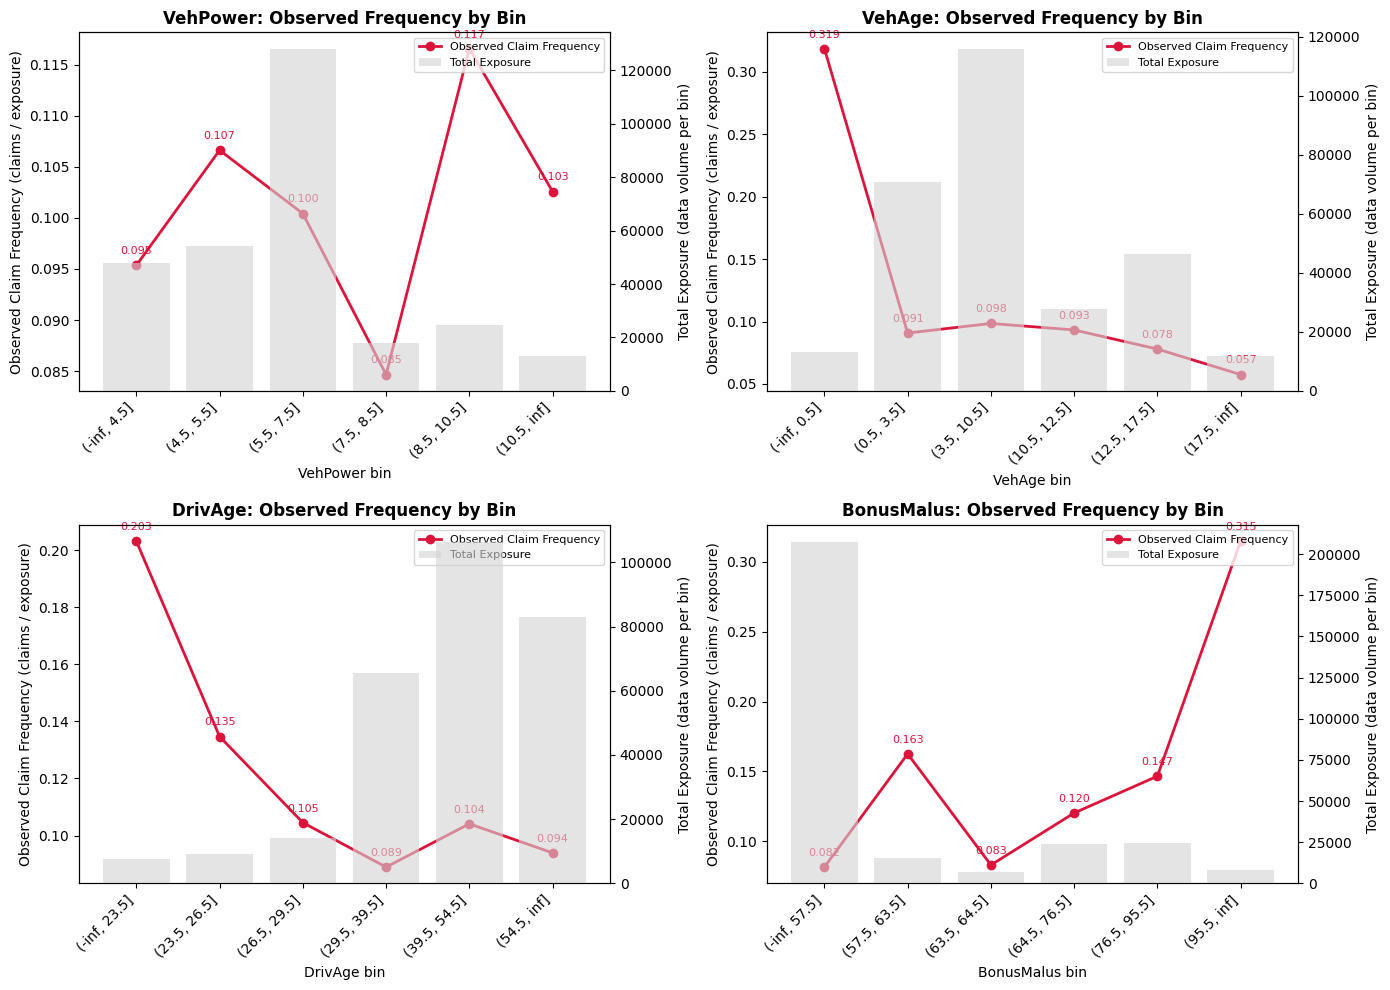

In [29]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for ax, col in zip(axes, bin_vars):
    summary = freq_train.groupby(f'{col}_bin', observed=True).apply(
        lambda g: pd.Series({
            'observed_freq': g['ClaimNb'].sum() / g['Exposure'].sum(),
            'exposure': g['Exposure'].sum()
        })
    ).reset_index()

    bar_labels = summary[f'{col}_bin'].astype(str)
    ax2 = ax.twinx()

    bars = ax2.bar(bar_labels, summary['exposure'], color='lightgray', alpha=0.6, zorder=1, label='Total Exposure')
    ax2.set_ylabel('Total Exposure (data volume per bin)')

    line, = ax.plot(bar_labels, summary['observed_freq'], color='crimson', marker='o',
                     linewidth=2, zorder=2, label='Observed Claim Frequency')
    ax.set_ylabel('Observed Claim Frequency (claims / exposure)')
    ax.set_xlabel(f'{col} bin')
    ax.set_title(f'{col}: Observed Frequency by Bin', fontsize=12, fontweight='bold')
    ax.set_xticklabels(bar_labels, rotation=45, ha='right')

    # Annotate each point with its exact frequency value
    for x, y in zip(bar_labels, summary['observed_freq']):
        ax.annotate(f'{y:.3f}', (x, y), textcoords="offset points", xytext=(0, 8),
                    ha='center', fontsize=8, color='crimson')

    # Combined legend pulling from both axes
    lines = [line, bars]
    ax.legend(lines, [l.get_label() for l in lines], loc='upper right', fontsize=8)

plt.tight_layout()
plt.show()

### Above chart confirms stepwise relationship of BonusMalus with claim frequency

# ============================================================
# GLM v3 — Tree-based binning + interaction term
# ============================================================
**What changed:**
- Replaced linear/polynomial terms for `VehPower`, `VehAge`, `DrivAge`,
  and `BonusMalus` with categorical bins. Bin edges were derived by
  fitting a shallow decision tree (exposure-weighted) to observed claim
  frequency per variable, then applying `pd.cut()` with those edges to
  both train and test sets (test uses train-derived edges — no leakage).
- Added one interaction term: `BonusMalus × DrivAge`.
- `Area` was considered but intentionally left out, consistent with v1/v2,
  to avoid collinearity with `log(Density)`.

**Why:** Observed-frequency-by-bin plots showed clearly non-monotonic
relationships (e.g. BonusMalus dips then climbs sharply; VehPower dips
then spikes) that a linear or quadratic GLM term structurally cannot fit.
Binning lets the GLM assign a separate coefficient per risk segment
instead of assuming a single global slope/curve shape.

**Bin edges used** (from `DecisionTreeRegressor`, exposure-weighted,
fit on training data only):
- VehPower: [4.5, 5.5, 7.5, 8.5, 10.5]
- VehAge: [0.5, 3.5, 10.5, 12.5, 17.5]
- DrivAge: [23.5, 26.5, 29.5, 39.5, 54.5]
- BonusMalus: [57.5, 63.5, 68.5, 76.5, 95.5]

In [30]:
from sklearn.tree import DecisionTreeRegressor

def get_tree_bins(train_df, col, max_leaf_nodes=6, min_samples_leaf=0.02):
    X = train_df[[col]].values
    y = train_df['ClaimNb'] / train_df['Exposure']  # observed frequency (rate)
    w = train_df['Exposure'].values                  # exposure as weight
    tree = DecisionTreeRegressor(max_leaf_nodes=max_leaf_nodes, min_samples_leaf=min_samples_leaf)
    tree.fit(X, y, sample_weight=w)
    thresholds = sorted(set(tree.tree_.threshold[tree.tree_.threshold != -2]))
    return [-np.inf] + thresholds + [np.inf]

bin_vars = ['VehPower', 'VehAge', 'DrivAge', 'BonusMalus']

bin_params = {
    'VehPower':   dict(max_leaf_nodes=6, min_samples_leaf=0.02),
    'VehAge':     dict(max_leaf_nodes=6, min_samples_leaf=0.02),
    'DrivAge':    dict(max_leaf_nodes=7, min_samples_leaf=0.02),
    'BonusMalus': dict(max_leaf_nodes=6, min_samples_leaf=0.04),
}

bins = {}
for col, params in bin_params.items():
    edges = get_tree_bins(freq_train, col, **params)
    bins[col] = edges
    freq_train[f'{col}_bin'] = pd.cut(freq_train[col], bins=edges)
    freq_test[f'{col}_bin']  = pd.cut(freq_test[col],  bins=edges)
    print(col, "-> bin edges:", edges)

VehPower -> bin edges: [-inf, np.float64(4.5), np.float64(5.5), np.float64(7.5), np.float64(8.5), np.float64(10.5), inf]
VehAge -> bin edges: [-inf, np.float64(0.5), np.float64(3.5), np.float64(10.5), np.float64(12.5), np.float64(17.5), inf]
DrivAge -> bin edges: [-inf, np.float64(23.5), np.float64(26.5), np.float64(29.5), np.float64(39.5), np.float64(54.5), np.float64(68.5), inf]
BonusMalus -> bin edges: [-inf, np.float64(57.5), np.float64(63.5), np.float64(68.5), np.float64(76.5), np.float64(95.5), inf]


In [31]:
bin_dummy_cols = []
for col in bin_vars:
    dummies_train = pd.get_dummies(freq_train[f'{col}_bin'], prefix=col, drop_first=True).astype(int)
    dummies_test  = pd.get_dummies(freq_test[f'{col}_bin'],  prefix=col, drop_first=True).astype(int)
    dummies_test  = dummies_test.reindex(columns=dummies_train.columns, fill_value=0)
    freq_train = pd.concat([freq_train, dummies_train], axis=1)
    freq_test  = pd.concat([freq_test,  dummies_test],  axis=1)
    bin_dummy_cols += list(dummies_train.columns)

freq_train['BonusMalus_x_DrivAge'] = freq_train['BonusMalus'].astype(float) * freq_train['DrivAge'].astype(float)
freq_test['BonusMalus_x_DrivAge']  = freq_test['BonusMalus'].astype(float)  * freq_test['DrivAge'].astype(float)

other_cols = [c for c in feature_cols if c not in bin_vars]
feature_cols_v3 = other_cols + bin_dummy_cols + ['BonusMalus_x_DrivAge']

In [32]:
X_train_v3 = sm.add_constant(freq_train[feature_cols_v3])
poisson_v3 = sm.GLM(freq_train['ClaimNb'], X_train_v3,
                     family=sm.families.Poisson(),
                     offset=np.log(freq_train['Exposure'])).fit()

X_test_v3 = sm.add_constant(freq_test[feature_cols_v3], has_constant='add')
freq_test['predicted_v3'] = poisson_v3.predict(X_test_v3, offset=np.log(freq_test['Exposure']))
freq_test['rate_v3'] = freq_test['predicted_v3'] / freq_test['Exposure']

print("Deviance v1:", poisson_results.deviance)
print("Deviance v2:", poisson_results_v2.deviance)
print("Deviance v3:", poisson_v3.deviance)
print()
print("Gini v3 (exposure-weighted):", gini(freq_test['ClaimNb'], freq_test['rate_v3'], freq_test['Exposure']))

Deviance v1: 173692.89842659797
Deviance v2: 173591.1747935341
Deviance v3: 169461.2110777773

Gini v3 (exposure-weighted): 0.29757965546079723


C:\Users\prish\AppData\Local\Temp\ipykernel_19840\1137262701.py:6: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  lorenz_area = np.trapz(df['cum_actual_pct'], df['cum_exposure_pct'])


**Result:** Deviance dropped meaningfully (173,591 → 169,461); Gini
(exposure-weighted) improved from 0.2478 → 0.2976. This is the largest
single improvement across all GLM versions, confirming that the
non-monotonic shape of these variables — not the linear specification —
was the main limiting factor in v1/v2.

**Status:** v3 is the Champion model going forward.